# WPdx label inspection

What this is: the Water Point Data Exchange labels we intend to train on, inspected before any
imagery is pulled. Feasibility is per class (see `docs/PLAN.md`), so every table here keeps the
class split visible.

Provenance: WPdx-Basic export retrieved **2026-11-17** from Socrata dataset `jfkt-jmqa`. Point
report dates run 1998-12-15 to 2024-12-01 in the training pool. Senegal has zero records, so the
Sahel scope here is Burkina Faso, Mali, Niger, Chad, Mauritania, Gambia.

Two files:

- `data/interim/wpdx_train_pool.parquet` — 263,877 points, dryland countries with dense coverage
- `data/interim/wpdx_sahel.parquet` — 3,141 points, the held-out Sahel scope

Kernel: `soberana-borehole-identification-venv`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
pool = pd.read_parquet(ROOT / 'data/interim/wpdx_train_pool.parquet')
sahel = pd.read_parquet(ROOT / 'data/interim/wpdx_sahel.parquet')
pool['scope'] = 'train_pool'
sahel['scope'] = 'sahel_holdout'
df = pd.concat([pool, sahel], ignore_index=True)

CLASSES = ['C1_borehole_handpump', 'C2_borehole_mechanized', 'C2b_borehole_standpost',
           'C3_borehole_untyped', 'other_water_point']
df['class'] = pd.Categorical(df['class'], categories=CLASSES, ordered=True)
print(df.shape)
df.dtypes

(267760, 19)


source                     str
lat_deg                float64
lon_deg                float64
report_date     datetime64[us]
status_id                  str
water_source               str
water_tech                 str
country_name            string
adm1                       str
adm2                       str
install_year           float64
management                 str
pay                        str
status                     str
class                 category
wpdx_class                 str
lat_r                  float64
lon_r                  float64
scope                      str
dtype: object

## 1. Class balance

C5 background does not exist in WPdx. It is sampled later, so the classes here are the three
borehole classes, the standpost class, plus `other_water_point` (dug wells, springs, gravity
schemes). The last one is **not** a negative for borehole detection unless the point is confirmed
to have no borehole.

In [2]:
counts = df.pivot_table(index='class', columns='scope', values='lat_deg',
                        aggfunc='size', observed=False).fillna(0).astype(int)
counts['total'] = counts.sum(axis=1)
counts.loc['TOTAL'] = counts.sum()
counts

scope,sahel_holdout,train_pool,total
class,,,
C1_borehole_handpump,813,77254,78067
C2_borehole_mechanized,1699,29049,30748
C2b_borehole_standpost,265,16896,17161
C3_borehole_untyped,206,48381,48587
other_water_point,158,93039,93197
TOTAL,3141,264619,267760


In [3]:
by_country = (df[df['scope'] == 'train_pool']
              .pivot_table(index='country_name', columns='class', values='lat_deg',
                           aggfunc='size', observed=False)
              .fillna(0).astype(int)
              .assign(total=lambda d: d.sum(axis=1))
              .sort_values('total', ascending=False))
by_country

class,C1_borehole_handpump,C2_borehole_mechanized,C2b_borehole_standpost,C3_borehole_untyped,other_water_point,total
country_name,,,,,,
Nigeria,57564,25068,18,11314,11153,105117
Uganda,5684,688,10848,32129,50138,99487
Kenya,1895,849,2038,3490,24566,32838
Ethiopia,5049,284,83,451,6418,12285
Benin,4124,0,3349,694,430,8597
Malawi,1928,8,2,0,18,1956
Niger,102,1065,45,115,38,1365
Ghana,197,453,293,97,158,1198
Burkina Faso,459,1,168,91,88,807


In [4]:
sahel_by_country = (df[df['scope'] == 'sahel_holdout']
                    .pivot_table(index='country_name', columns='class', values='lat_deg',
                                 aggfunc='size', observed=False)
                    .fillna(0).astype(int))
sahel_by_country

class,C1_borehole_handpump,C2_borehole_mechanized,C2b_borehole_standpost,C3_borehole_untyped,other_water_point
country_name,,,,,
Burkina Faso,459,1,168,91,88
Chad,16,10,0,0,19
Gambia,130,0,0,0,0
Mali,106,616,52,0,6
Mauritania,0,7,0,0,7
Niger,102,1065,45,115,38


## 2. Report dates

A label is a claim about a moment. `report_date` is that moment. Imagery for each point must be
matched to it, or the label describes a pump that may not have existed yet.

                     min     median        max   count
scope                                                 
sahel_holdout 2003-02-15 2014-11-16 2022-03-04    3141
train_pool    1998-12-15 2015-01-28 2024-12-01  264619


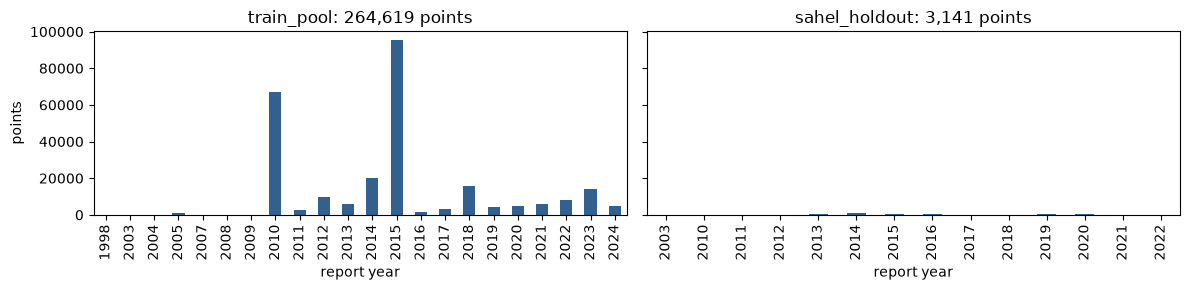

In [5]:
df['year'] = df['report_date'].dt.year
print(df.groupby('scope', observed=True)['report_date'].agg(['min', 'median', 'max', 'count']))

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, scope in zip(axes, ['train_pool', 'sahel_holdout']):
    d = df[df['scope'] == scope]
    d['year'].value_counts().sort_index().plot.bar(ax=ax, color='#33618f')
    ax.set_title(f'{scope}: {len(d):,} points')
    ax.set_xlabel('report year')
    ax.set_ylabel('points')
plt.tight_layout()
plt.show()

## 3. Geography

Where the points sit, and which countries give usable volume. Senegal is absent by construction.

          lat_deg     lon_deg
count  267760.000  267760.000
mean        5.085      21.376
std         4.991      13.715
min       -23.546     -16.755
25%         0.739       7.835
50%         3.672      30.552
75%         9.307      33.818
max        30.938      47.319


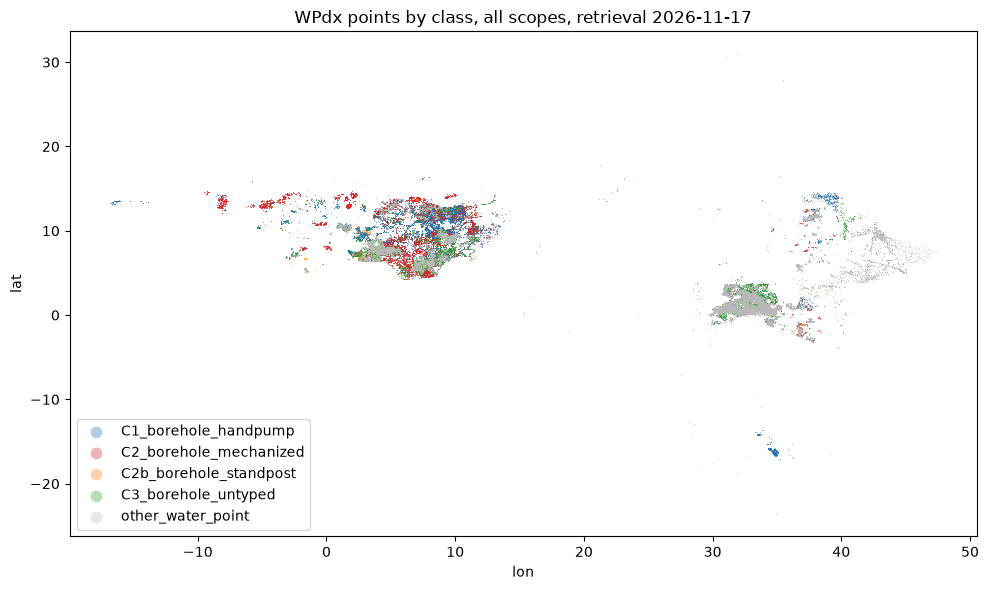

In [6]:
print(df[['lat_deg', 'lon_deg']].describe().round(3))

fig, ax = plt.subplots(figsize=(10, 6))
colors = {'C1_borehole_handpump': '#1f77b4', 'C2_borehole_mechanized': '#d62728',
          'C2b_borehole_standpost': '#ff7f0e', 'C3_borehole_untyped': '#2ca02c',
          'other_water_point': '#bbbbbb'}
for cls, col in colors.items():
    d = df[df['class'] == cls]
    ax.scatter(d['lon_deg'], d['lat_deg'], s=0.5, c=col, label=cls, alpha=0.35, linewidths=0)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
ax.legend(markerscale=12, loc='lower left')
ax.set_title('WPdx points by class, all scopes, retrieval 2026-11-17')
plt.tight_layout()
plt.show()

## 4. The sampling trap

WPdx clusters where surveys happened, not where boreholes are. Uniform random sampling of 500
points would land mostly in a handful of dense survey blocks, and imagery from those blocks would
be nearly redundant. This measures how bad the clustering is: points per 0.1° cell (about 11 km),
and how many labels sit on top of each other.

In [7]:
for scope in ['train_pool', 'sahel_holdout']:
    d = df[df['scope'] == scope]
    cell = (d['lat_deg'].round(1).astype(str) + '_' + d['lon_deg'].round(1).astype(str))
    per_cell = cell.value_counts()
    print(f'{scope}: {len(d):,} points in {len(per_cell):,} cells of 0.1 deg')
    print(f'  points per cell: median {per_cell.median():.0f}, p95 {per_cell.quantile(.95):.0f}, '
          f'max {per_cell.max()}')
    print(f'  cells holding 50% of points: {int((per_cell.sort_values(ascending=False).cumsum() <= len(d) / 2).sum())}')

top = (df[df['scope'] == 'train_pool']
       .assign(cell=lambda d: d['lat_deg'].round(1).astype(str) + '_' + d['lon_deg'].round(1).astype(str))
       .groupby(['cell', 'country_name']).size().sort_values(ascending=False).head(10))
top

train_pool: 264,619 points in 9,928 cells of 0.1 deg
  points per cell: median 7, p95 114, max 869
  cells holding 50% of points: 709
sahel_holdout: 3,141 points in 723 cells of 0.1 deg
  points per cell: median 2, p95 15, max 55
  cells holding 50% of points: 94


cell       country_name
0.0_29.8   Uganda          869
0.2_34.5   Kenya           782
11.8_38.1  Ethiopia        777
1.0_34.3   Uganda          775
0.3_34.3   Kenya           691
0.4_34.3   Kenya           670
0.1_34.8   Kenya           649
12.0_8.5   Nigeria         634
-0.1_30.4  Uganda          629
0.6_30.2   Uganda          604
dtype: int64

In [8]:
def nn_distances_m(frame: pd.DataFrame) -> np.ndarray:
    rad = np.radians(frame[['lat_deg', 'lon_deg']].to_numpy())
    tree = BallTree(rad, metric='haversine')
    dist, _ = tree.query(rad, k=2)
    return dist[:, 1] * 6371000.0

for scope in ['train_pool', 'sahel_holdout']:
    d = df[df['scope'] == scope].reset_index(drop=True)
    d['nn_m'] = nn_distances_m(d)
    print(f'{scope}: nearest other label within 50 m: {(d["nn_m"] < 50).mean():.1%}, '
          f'within 100 m: {(d["nn_m"] < 100).mean():.1%}, median {d["nn_m"].median():.0f} m')
    df.loc[df['scope'] == scope, 'nn_m'] = d['nn_m'].to_numpy()

train_pool: nearest other label within 50 m: 25.0%, within 100 m: 35.4%, median 187 m
sahel_holdout: nearest other label within 50 m: 10.0%, within 100 m: 17.3%, median 425 m


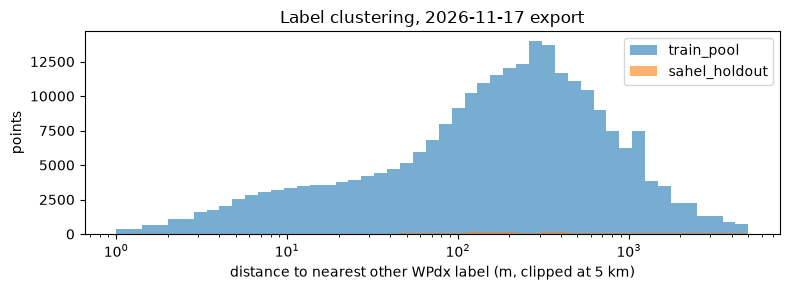

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
for scope in ['train_pool', 'sahel_holdout']:
    v = df.loc[df['scope'] == scope, 'nn_m'].clip(upper=5000)
    ax.hist(v, bins=np.logspace(0, np.log10(5000), 50), alpha=0.6, label=scope)
ax.set_xscale('log')
ax.set_xlabel('distance to nearest other WPdx label (m, clipped at 5 km)')
ax.set_ylabel('points')
ax.legend()
ax.set_title('Label clustering, 2026-11-17 export')
plt.tight_layout()
plt.show()

## 5. Attribute quality

The class comes from free text in `water_source` and `water_tech`. Missing tech means the point
cannot be split into C1 and C2, which is why C3 exists. Read the raw strings before trusting the
regex.

In [10]:
cols = ['report_date', 'water_source', 'water_tech', 'status', 'install_year', 'management', 'pay']
(df.groupby('scope', observed=True)[cols].apply(lambda d: d.isna().mean())
   .T.round(3))

scope,sahel_holdout,train_pool
report_date,0.000,0.000
water_source,0.077,0.027
water_tech,0.594,0.522
status,0.894,0.281
install_year,0.238,0.427
management,0.855,0.394
pay,0.902,0.494


In [11]:
for cls in CLASSES:
    print(f'--- {cls} (train_pool) ---')
    print(df[(df['scope'] == 'train_pool') & (df['class'] == cls)]['water_tech']
          .value_counts().head(8).to_string(), '\n')

--- C1_borehole_handpump (train_pool) ---
water_tech
Hand pump               59922
India_Mark_II            1667
Pump Vergnet HPV 60      1642
Afridev Handpump         1632
Manual (hand pump)       1486
India Mark II             942
Pump Vergnet HPV 100      906
Hand Pump Afridev         892 

--- C2_borehole_mechanized (train_pool) ---
water_tech
Motorised            24697
Submersible pump       439
Submersible pump.      247
Solar                  212
electrical_pump         78
Submersible             77
solar                   70
Solar power             56 

--- C2b_borehole_standpost (train_pool) ---
water_tech
Postes d'eaux autonomes (PEA) privés             3347
KIOSK, public tap                                1621
tap stand                                         366
Tapstand                                          149
Borne fontaine                                    147
Public tap stand                                  112
Gravity Fed System|Kiosk or Public stand Post     110

In [12]:
pd.crosstab(df['class'], df['status'], normalize='index').round(3)

status,0,1,20litre jerrycan cannot properly stand on the tap while fetching water,APARENTLY IT'S FOR INSTITUTIONAL CONSUMPTION AND A FEW NEIGHBORHOOD,Abandonn? Dis ponibilité en eau Intermittent,Abandonn? Dis ponibilité en eau Intermittent Compl?tement abandonn?,Abandonn? Dis ponibilité en eau Intermittent IL Y A APPARUTOON DU LAVE DANS L'EAU,Abandonn? Dis ponibilité en eau Intermittent MAUVAIS ETAT,Abandonn? Dis ponibilité en eau Intermittent bon potable bonne,Abandonn? Dis ponibilité en eau Intermittent l'eau est SAL?E,...,the absence of water,the absence of yusiel,the dam was expected to solve water problem if the are but still incomplete.it has no inlet to collect water.water seen in the pan is only a collection from the top.,there is no water,theres a minor maintenance Normal,to cut the fouset,under breakdown since Feb 2O17N Does Not Function Need of maintenance by experts,water table is very low Poor,water treatment,watert table very low Does Not Function
class,,,,,,,,,,,,,,,,,,,,,
C1_borehole_handpump,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C2_borehole_mechanized,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C2b_borehole_standpost,0.006,0.020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C3_borehole_untyped,0.008,0.023,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
other_water_point,0.022,0.022,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. What this tells us

Read the tables above and write the numbers down; any probe sample must be stratified by country
and coarse grid cell, not drawn uniformly. The immediate next step is the probe sampler, which
writes `data/interim/probe_sample.parquet`: 500 positives per borehole class plus 500 background
points at least 500 m from any label, keeping `country_name` as the split group.